# Applying sLORETA on individual data

# Batch Wise Run
Run the code for all subjects of a given dataset.

## 📦 Imports

In [1]:
import mindmap as mm 
from pathlib import Path

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `eeg`: Preprocessed EEG
- `fwd`: Forward operator

🛠️ **<font color=violet>Configuration</font>**:
- `fconfig`: Configuration file.

🛠️ **<font color=violet>EEG</font>**:
- `win_size`: Time window size around EEG peak in [s]

🛠️ **<font color=violet>sLORETA</font>**:
- `lam`: Smoothing regularizer.

🛠️ **<font color=violet>Other options</font>**:
- `overwrite`: Overwrite existing sLORETA solution with same smoothing regularizing parameter.

In [2]:
############## Parameters #################
# configuration
fconfig = "../configurations/spike.yml"

# EEG
win_size = 0.1

# sLORETA
lam = 0.01

# others
overwrite = True
###########################################

# configuration
config   = mm.io.read_config(fconfig)
subjects = config["SUBS"]
samples  = config["SAMP"]
mm_dir   = Path(config["MM_DIR"])

# file naming
fstc = lambda sub, samp: mm_dir/sub/"inv"/f"{sub}-{samp}_sloreta-{lam}"

## ♾️ Loop

In [3]:
for sub in subjects:
    for samp in samples: 
        # check file existence
        fname = fstc(sub, samp)
        if fname.exists() and not overwrite:
            print(f"\033[93msLORETA solution already exists for subject {sub} with lam={lam}\033[0m")
            continue 
        if not fname.parent.exists():
            fname.parent.mkdir(parents=True)

        try:
            data = mm.io.read_dataset(sub, "eeg", "fwd", sample=samp)
            stc  = mm.sloreta(data["eeg"], data["fwd"], lam, win_size)
        except Exception as e:
            print(f"\033[91mFailed to compute sLORETA solution for subject '{sub}', sample '{samp}' due to {e}\033[0m")
            continue

        # save
        stc.save(fname, overwrite=True, verbose="warning")
        print(f"\033[92mSuccessfully computed sLORETA inverse solution for subject '{sub}', sample '{samp}'\033[0m")

Preprocessed EEG not found, reading raw instead.
Failed to compute sLORETA solution for subject 'sub-pat01', sample 'spike' due to File does not exist: "/media/nino/DATA/SPIKE/derivatives/mindmap/sub-pat01/fwd/sub-pat01_fwd.fif"
Preprocessed EEG not found, reading raw instead.
DATA SUMMARY
Dataset: spike
Subject: sub-pat02
Retrieved objects:
- fwd
- eeg
Missing objects:
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
Successfully computed sLORETA inverse solution for subject 'sub-pat02', sample 'spike'
Preprocessed EEG not found, reading raw instead.
DATA SUMMARY
Dataset: spike
Subject: sub-pat03
Retrieved objects:
- fwd
- eeg
Missing objects:
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not b

# Step Wise Run

Run the code step by step for a single subject.

## 📦 Imports

In [1]:
import mindmap as mm
import mne
import numpy as np
from pathlib import Path

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `eeg`: Preprocessed EEG
- `fwd`: Forward operator
- `gt`: Ground truth (optional)
- `resec`: Resection area (optional)
- `cst`: Connectome spectrum transform (optional) 

🛠️ **<font color=violet>Configuration</font>**:
- `fconfig`: Configuration file.
- `sub`: Subject id
- `sample`: sample id

In [2]:
################## Parameters ##################
# configuration
fconfig = "../../papers/spike/configuration.yml"
sub     = 25 
samp    = 0
################################################

reader = mm.io.dataset_reader(fconfig)

data = reader(sub, "eeg", "fwd", "gt", "resec", "cst", sample=samp)

# noise covariance (should be computed before and be a variable but I haven't gotten any epoch/raw EEG ever so far)
noise_cov = mne.make_ad_hoc_cov(data["eeg"].info, std={"eeg":1})

# times of interest
hrp_time  = mm.utils.eeg_rising_phase(data["eeg"], ratio=0.5)   # half rising phase
peak_time = mm.utils.eeg_rising_phase(data["eeg"], ratio=1)

# set reference
_ = data["eeg"].set_eeg_reference(projection=True)

DATA SUMMARY
Dataset: spike
Subject: sub-pat25
Retrieved objects:
- eeg
- fwd
- cst
- resec
Missing objects:
- gt
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.


## EEG

🌟 **Topographic map at 50% rising phase**

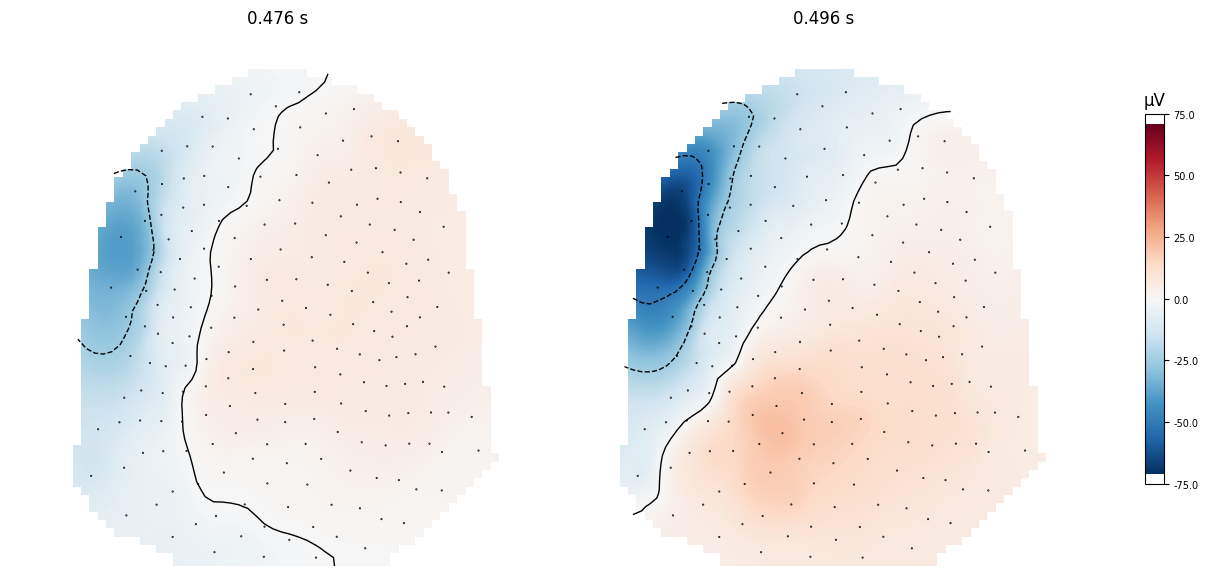

In [3]:
times = [hrp_time, peak_time]
_ = data["eeg"].plot_topomap(times=times, size=4, extrapolate="local", outlines=None)

🛠️ <font color=violet>**Time window**</font>:
- `win_size`: Time window size around EEG peak in [s]

Number of samples: 77


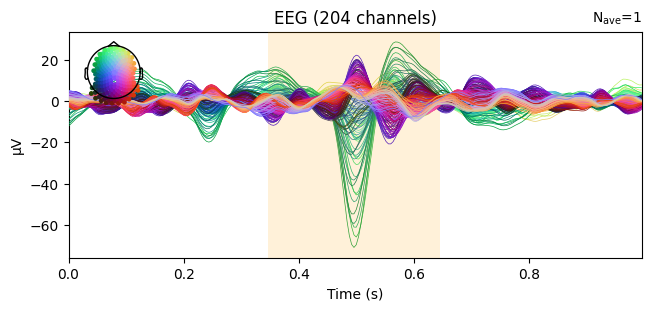

In [4]:
################### Parameters ####################
win_size = 0.3
###################################################


if win_size:
    eeg = data["eeg"].copy()
    dt  = win_size/2
    eeg = eeg.crop(peak_time-dt, peak_time+dt)

    highlight = [peak_time-dt, peak_time+dt]

else:
    eeg = data["eeg"].copy()
    highlight = None 

print(f"Number of samples: {eeg.data.shape[1]}")
_ = data["eeg"].plot(highlight=highlight)

## sLORETA solution
#### ⚙️ <font color=green>**Solve inverse problem**</font>
🛠️ <font color=violet>**sLORETA**</font>:
- `lam`: Parameter of smoothing regularizer

In [5]:
#################### Parameters ################
lam = 0.01
################################################

inverse = mne.minimum_norm.make_inverse_operator(
    eeg.info,
    data["fwd"],
    noise_cov,
    fixed   = True,
    depth   = None,
    verbose = "warning",
)

stc = mne.minimum_norm.apply_inverse(
    eeg, 
    inverse, 
    lambda2 = lam,
    method  = "sLORETA",
    verbose = "warning",
)

🌟 **Visualize solution** <br>

In [6]:
try:
    overlay = data["resec"]
except:
    overlay = None 

try: 
    ground_truth = data["gt"]
    ground_truth = ground_truth.crop(stc.times[0], stc.times[-1])
    signals = [stc, ground_truth]
    titles  = ["CSET", "Ground Truth"]
except:
    signals = stc 
    titles  = "CSET"

print(f"Half rising phase time: {hrp_time}")
print(f"Peak time: {peak_time}")

mm.viz.plot_brain(data["fwd"]["src"], signals, title=titles, absolute=True, overlay=overlay, overlay_size=1, overlay_opacity=1, smooth_shading=True).show()

Half rising phase time: 0.476
Peak time: 0.496


Widget(value='<iframe src="http://localhost:42355/index.html?ui=P_0x727c27189e50_0&reconnect=auto" class="pyvi…

In [14]:
idx = stc.time_as_index(time)
mm.viz.plot_spectrum(data["cst"]@stc.data[:,idx])

In [7]:
plotter = mm.viz.plot_brain(data["fwd"]["src"], stc.data[:,10])
plotter.camera_position = "zy"
plotter.camera.roll += 90
plotter.camera.zoom(1.5)
plotter.show()

Widget(value='<iframe src="http://localhost:42355/index.html?ui=P_0x727c237825d0_1&reconnect=auto" class="pyvi…

In [9]:
activity = stc.copy()
activity = activity.crop(0.455, 0.544)

mm.viz.brain_gif(data["fwd"]["src"], np.abs(activity.data), "sloreta.gif", camera_position="zy", roll=90, zoom=1.5, fps=5)

💾 **Save the sLORETA solution** <br>
🛠️ <font color=violet>**Options**</font>:
- `overwrite`: Overwrite existing files.

In [92]:
############### Parameters #################
overwrite = True
############################################

fname = mm_dir/sub/"inv"/f"{sub}_{samp}_sloreta-{lam}"

if not fname.parent.exists():
    fname.parent.mkdir(parents=True)

stc.save(fname, overwrite=overwrite)  
print(f"\033[92mSuccessfully saved sLORETA solution for subject '{sub}', sample '{samp}' with lam={lam}.")

NameError: name 'mm_dir' is not defined

## Ground Truth
🌟 **Brain** <br>
🛠️ <font color=violet>**Time point**</font>
- `tp`: time point to visualize (`thalf` or `tpeak`), if None then whole time serie is shown

In [110]:
################ Parameters #################
tp = ht
#############################################

if "gt" in data.keys():
    if tp is None:
        mm.viz.plot_brain_time_series(data["fwd"]["src"], data["gt"].data, sfreq=sfreq)
    else:
        mm.viz.plot_brain_signal(data["fwd"]["src"], np.abs(data["gt"].data[:,tp]), cmap="reds").show()

else:
    plotter = mm.viz.plot_resection(data["fwd"]["src"], data["resec"], color="red")
    plotter.add_legend(face="circle")
    plotter.show()

Widget(value='<iframe src="http://localhost:42055/index.html?ui=P_0x79a4a307e5d0_44&reconnect=auto" class="pyv…

🌟 **Connectome Spectrum** <br>
🛠️ <font color=violet>**Time point**</font>
- `tp`: time point to visualize (`ht` or `pt`), if None then whole time serie is shown

In [111]:
################ Parameters #################
tp = ht
#############################################

if "gt" in data.keys():
    mm.viz.plot_spectrum(data["cst"]@data["gt"].data[:,ht]).show()

In [112]:
test = stc.crop(t_half, t_half).data.squeeze()
mm.viz.plot_brain_signal(data["fwd"]["src"], np.abs(test), cmap="reds").show()

Widget(value='<iframe src="http://localhost:42055/index.html?ui=P_0x79a4b473c8f0_45&reconnect=auto" class="pyv…